# Plantilla y Generador de Gráficos Estandarizados (Informe Villa Gaucho)

Este cuaderno contiene las herramientas para generar los gráficos de torta, barras horizontales, barras verticales, histogramas continuos y barras particionadas/apiladas con el diseño y formato exacto del **Informe de Villa Gaucho**, con todo el código documentado y comentado paso a paso para que puedas entender y modificar fácilmente cualquier parámetro.

---

### Especificaciones de Diseño Implementadas:
1. **Tipografía y Tamaño de Letra 14**:
   - Todo el gráfico e informe utiliza fuente en tamaño **14** (títulos, ejes, frecuencias dentro/fuera de las barras y tortas, porcentajes y etiquetas).
2. **Gráficos de Torta (Formato exacto Villa Gaucho)**:
   - **Líneas blancas divisorias** entre las porciones de la torta (`edgecolor='white', linewidth=1.5`).
   - **Porcentajes adentro** de la torta (en negrita, tamaño 14, formato `X,X%`).
   - **Línea conectora con doblez en 2 tramos (diagonal + horizontal)**:
     - Comienza con un punto indicador gris sobre la cuña.
     - Pasa por un codo en el exterior y se proyecta horizontalmente.
     - **Finaliza exactamente donde comienza el texto de la categoría** (sin subrayar por debajo).
   - **Nombre de la categoría arriba** de la línea y **frecuencia absoluta con su unidad abajo** de la línea (ej. `158 hogares`, `1 hogar`).
   - **Distribución balanceada en el recuadro**: algoritmo de separación vertical equitativa para evitar que las etiquetas se solapen o queden apretadas.
   - **Regla de más de 5 categorías**: Si la variable tiene más de 5 categorías (`max_categorias_torta=5`), conmuta automáticamente a un **gráfico de barras horizontales** que utiliza exactamente la misma paleta y orden de colores que el gráfico de torta.
   - **Orden de mayor a menor porcentaje** con la paleta de colores:
     1. **Azul** (`#4285F4`)
     2. **Naranja** (`#FB8C00`)
     3. **Verde** (`#34A853`)
     4. **Amarillo** (`#FBBC05`)
     5. **Violeta** (`#8E24AA`)
     6. **Beige** (`#D7CCC8`)
   - Para preguntas de **positivo y negativo** (ej: Sí / No): **Positivo = Azul (`#4285F4`)**, **Negativo = Naranja (`#FB8C00`)**.
3. **Gráficos de Barras (Horizontales y Verticales)**:
   - **Regla del 2%**:
     - Si el porcentaje es **menor a 2%** (`porcentaje < 2.0`), la frecuencia absoluta y el porcentaje aparecen **afuera de la barra** (`"X (Y,Y%)"`).
     - Si el porcentaje es **mayor o igual a 2%**, la frecuencia absoluta se muestra **adentro de la barra** (en blanco y negrita, tamaño 14) y el porcentaje afuera.
   - **Color de barras de un solo tono**: **`#1b7882`**.
   - Opción `usar_colores_torta=True` para usar la misma paleta ordenada del gráfico de torta en barras horizontales.
4. **Histogramas Continuos (Variables Cuantitativas Continuas, ej. Edad, Ingresos, Tiempo)**:
   - **Barras continuas unidas** (`width=1.0`), **sin separación física entre barras**.
   - Borde del mismo color pero un **40% más oscuro** (`#10484e`), con un ancho de **`0.1`**.
5. **Gráficos de Barras Particionadas (Apiladas / Bivariadas)**:
   - Permite analizar la composición de una variable categórica según rangos u otra variable (ej. Rango de Edad vs. Composición de Salud o Patologías).
   - Barras horizontales apiladas con líneas blancas divisorias (`edgecolor='white', linewidth=1.2`).
   - Las categorías se colorean según la **paleta de la torta (`PALETA_TORTA`) ordenada de mayor a menor porcentaje total**: 1. Azul (`#4285F4`), 2. Naranja (`#FB8C00`), 3. Verde (`#34A853`), 4. Amarillo (`#FBBC05`), 5. Violeta (`#8E24AA`), 6. Beige (`#D7CCC8`).
   - **Frecuencias absolutas adentro de cada segmento** en blanco y negrita (mostrando solo valores > 0).
   - **Leyenda lateral derecha** con título, Total general $N$, y para cada categoría el conteo y su porcentaje total (`n = X, Y,Y%`).
   - Tamaño de letra **14** en títulos, ejes, marcas y leyenda.


In [1]:
# ==============================================================================
# CONFIGURACIÓN GLOBAL Y LIBRERÍAS
# ==============================================================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors

# Configuramos matplotlib para que TODOS los textos por defecto tengan tamaño 14
plt.rcParams['font.size'] = 14          # Tamaño de letra base
plt.rcParams['axes.titlesize'] = 14     # Tamaño del título del gráfico
plt.rcParams['axes.labelsize'] = 14     # Tamaño de etiquetas en los ejes X e Y
plt.rcParams['xtick.labelsize'] = 14    # Tamaño de los valores del eje X
plt.rcParams['ytick.labelsize'] = 14    # Tamaño de los valores del eje Y
plt.rcParams['legend.fontsize'] = 14    # Tamaño de la leyenda
plt.rcParams['figure.titlesize'] = 14   # Tamaño del título de la figura

# ==============================================================================
# PALETA DE COLORES ESTANDARIZADA
# ==============================================================================
# Paleta para tortas: asignada estrictamente de mayor a menor porcentaje:
# 1. Azul, 2. Naranja, 3. Verde, 4. Amarillo, 5. Violeta, 6. Beige
PALETA_TORTA = [
    '#4285F4',  # 1. Azul (Color institucional / Google)
    '#FB8C00',  # 2. Naranja
    '#34A853',  # 3. Verde
    '#FBBC05',  # 4. Amarillo
    '#8E24AA',  # 5. Violeta
    '#D7CCC8'   # 6. Beige
]

# Color específico para gráficos de barra e histogramas continuos
COLOR_BARRAS_UNICO = '#1b7882'

# Colores para preguntas binarias (Positivo vs Negativo)
COLOR_POSITIVO = '#4285F4'  # Azul para respuesta afirmativa / positiva
COLOR_NEGATIVO = '#FB8C00'  # Naranja para respuesta negativa

# ==============================================================================
# FUNCIÓN AUXILIAR: OSCURECER COLOR
# ==============================================================================
def oscurecer_color(color_hex, factor_oscuridad=0.40):
    """
    Toma un color hexadecimal y devuelve el mismo color oscurecido en la proporción indicada.
    Por ejemplo, con factor_oscuridad=0.40, devuelve el color 40% más oscuro.
    """
    rgb = mcolors.to_rgb(color_hex)
    return tuple(c * (1.0 - factor_oscuridad) for c in rgb)


## 1. Función para Gráficos de Torta Estandarizados (con Conmutación Automática si > 5 categorías)
- Si tiene más de 5 categorías (`len(categorias) > max_categorias_torta` y `conmutar_si_muchas_categorias=True`), genera un gráfico de **barras horizontales con los mismos colores de la torta**.
- Si tiene 5 o menos categorías, genera el gráfico de torta estandarizado.
- La línea guía **conecta directamente al punto donde comienza el texto** (sin subrayar).


In [ ]:
def graficar_torta(categorias, valores, titulo="", unidad="personas", es_binario=False, orden_positivo_primero=True, figsize=(10, 6), max_categorias_torta=5, conmutar_si_muchas_categorias=True, **kwargs):
    """
    Genera un gráfico de torta con el formato del Informe de Villa Gaucho:
    - Paleta ordenada de mayor a menor: Azul (#4285F4), Naranja (#FB8C00), Verde (#34A853), Amarillo (#FBBC05), Violeta (#8E24AA), Beige (#D7CCC8).
    - Si es binario (Sí/No): Positivo = Azul, Negativo = Naranja.
    - Porcentajes ADENTRO de la torta (en negrita, tamaño 14, formato X,X%).
    - Frecuencias absolutas AFUERA de la torta (debajo de la línea conectora con su unidad singular/plural).
    - Nombre de la categoría AFUERA de la torta (arriba de la línea conectora).
    - Líneas blancas divisorias entre porciones de la torta (edgecolor='white', linewidth=1.5).
    - Línea conectora en 2 tramos con codo (diagonal + horizontal) que arranca de un punto indicador en la cuña
      y finaliza exactamente donde comienza el texto de la categoría, sin subrayar.
    - Distribución vertical balanceada para evitar superposiciones entre categorías cercanas.
    - Si la variable posee más de 5 categorías y conmutar_si_muchas_categorias=True, conmuta automáticamente
      a un gráfico de barras horizontales con la paleta de torta.
    """
    df_temp = pd.DataFrame({'categoria': [str(c) for c in categorias], 'fi': list(valores)})

    # Conmutación automática si hay más de 5 categorías
    if conmutar_si_muchas_categorias and len(df_temp) > max_categorias_torta and not es_binario and 'graficar_barras_horizontales' in globals():
        print(f"[INFO] La variable tiene {len(df_temp)} categorías (> {max_categorias_torta}). Se grafica con barras horizontales usando la paleta de torta.")
        graficar_barras_horizontales(
            etiquetas=df_temp['categoria'],
            valores=df_temp['fi'],
            titulo=titulo,
            usar_colores_torta=True,
            ordenar_mayor_a_menor=True,
            figsize=(13, max(6, len(df_temp) * 0.8))
        )
        return

    # Asignación de colores y orden
    if es_binario:
        def es_pos(val):
            val_clean = str(val).strip().lower()
            return val_clean in ['si', 'sí', 'positivo', 'true', 'afirma', 'posee', 'tiene', 'concurre']

        df_temp['es_pos'] = df_temp['categoria'].apply(es_pos)
        if orden_positivo_primero:
            df_temp = df_temp.sort_values(by='es_pos', ascending=False).reset_index(drop=True)
        colores = [COLOR_POSITIVO if p else COLOR_NEGATIVO for p in df_temp['es_pos']]
    else:
        df_temp = df_temp.sort_values(by='fi', ascending=False).reset_index(drop=True)
        colores = [PALETA_TORTA[i % len(PALETA_TORTA)] for i in range(len(df_temp))]

    cats = df_temp['categoria'].tolist()
    vals = df_temp['fi'].values

    fig, ax = plt.subplots(figsize=figsize, subplot_kw=dict(aspect="equal"))

    # Torta con líneas divisorias blancas y porcentajes adentro
    wedges, texts, autotexts = ax.pie(
        vals,
        autopct=lambda p: f"{p:.1f}%".replace('.', ','),
        pctdistance=0.72,
        colors=colores,
        startangle=90,
        counterclock=False,
        wedgeprops=dict(width=1, edgecolor='white', linewidth=1.5)
    )

    # Estilo porcentajes interiores (tamaño 14 y negrita)
    for at in autotexts:
        at.set_color('#1a1a1a')
        at.set_fontsize(14)
        at.set_fontweight('bold')

    # Calcular posiciones angulares y lados
    elementos = []
    for i, p in enumerate(wedges):
        ang = (p.theta2 - p.theta1) / 2.0 + p.theta1
        x = np.cos(np.deg2rad(ang))
        y = np.sin(np.deg2rad(ang))
        lado = -1 if x < 0 else 1

        elementos.append({
            'i': i,
            'x': x,
            'y': y,
            'lado': lado,
            'y_afuera': 1.15 * y
        })

    # Separación vertical balanceada para evitar solapamientos
    min_sep = 0.29
    y_min, y_max = -1.22, 1.24
    for lado_actual in (-1, 1):
        grupo = [e for e in elementos if e['lado'] == lado_actual]
        if len(grupo) <= 1:
            continue
        grupo.sort(key=lambda e: e['y_afuera'])
        for k in range(1, len(grupo)):
            if grupo[k]['y_afuera'] - grupo[k - 1]['y_afuera'] < min_sep:
                grupo[k]['y_afuera'] = grupo[k - 1]['y_afuera'] + min_sep
        if grupo[-1]['y_afuera'] > y_max:
            grupo[-1]['y_afuera'] = y_max
            for k in range(len(grupo) - 2, -1, -1):
                if grupo[k + 1]['y_afuera'] - grupo[k]['y_afuera'] < min_sep:
                    grupo[k]['y_afuera'] = grupo[k + 1]['y_afuera'] - min_sep
        if grupo[0]['y_afuera'] < y_min:
            ys = np.linspace(y_min, y_max, len(grupo))
            for k, e in enumerate(grupo):
                e['y_afuera'] = ys[k]

    # Líneas guía en 2 tramos (diagonal -> horizontal) que arrancan justo en el texto sin subrayar
    for e in elementos:
        i = e['i']
        x = e['x']
        y = e['y']
        lado = e['lado']
        y_afuera = e['y_afuera']

        # Punto sobre la cuña
        x_punto, y_punto = 0.85 * x, 0.85 * y
        x_afuera = 1.35 * lado

        # Codo donde la línea pasa de diagonal a horizontal (fuera del círculo)
        r_ext = 1.08 if abs(y_afuera - 1.15 * y) > 1e-6 else 1.15
        x_min_ext = np.sqrt(max(0.0, r_ext**2 - y_afuera**2))
        x_codo = lado * max(abs(1.15 * x), x_min_ext)
        y_codo = y_afuera

        # Fin de la recta horizontal dejando margen justo donde inicia el texto (sin subrayar)
        x_fin = x_afuera - 0.03 * lado

        # Punto gris indicador sobre la cuña
        ax.plot(x_punto, y_punto, marker='o', markersize=4, color='#8c8c8c', zorder=4)

        # Línea guía en 2 tramos: diagonal (punto -> codo) + horizontal (codo -> inicio del texto)
        ax.plot(
            [x_punto, x_codo, x_fin],
            [y_punto, y_codo, y_codo],
            color='#8c8c8c',
            lw=1.2,
            solid_joinstyle='round',
            zorder=2
        )

        # Formato de cantidad y unidad singular / plural
        cant = int(vals[i])
        if not unidad:
            texto_unidad = str(cant)
        elif cant == 1:
            if unidad.lower() == 'integrantes':
                palabra_unidad = 'integrante'
            elif unidad.lower() == 'hogares':
                palabra_unidad = 'hogar'
            elif unidad.lower() == 'personas':
                palabra_unidad = 'persona'
            elif unidad.endswith('es') and not unidad.endswith('tes'):
                palabra_unidad = unidad[:-2]
            elif unidad.endswith('s'):
                palabra_unidad = unidad[:-1]
            else:
                palabra_unidad = unidad
            texto_unidad = f"{cant} {palabra_unidad}"
        else:
            texto_unidad = f"{cant} {unidad}"

        alineacion_h = "right" if lado == -1 else "left"

        # 1. Nombre de la categoría ARRIBA de la línea
        ax.text(
            x_afuera,
            y_afuera + 0.015,
            cats[i],
            horizontalalignment=alineacion_h,
            verticalalignment="bottom",
            fontsize=14,
            color="#202124",
            fontweight='medium'
        )

        # 2. Frecuencia absoluta y unidad ABAJO de la línea
        ax.text(
            x_afuera,
            y_afuera - 0.035,
            texto_unidad,
            horizontalalignment=alineacion_h,
            verticalalignment="top",
            fontsize=14,
            color="#70757a"
        )

    if titulo:
        ax.set_title(titulo, fontsize=14, pad=20, fontweight='bold', color='#202124')

    ax.set_xlim(-1.95, 1.95)
    ax.set_ylim(-1.35, 1.35)
    plt.subplots_adjust(left=0.1, right=0.9, top=0.9, bottom=0.1)
    plt.show()


## 2. Gráficos de Barras Estandarizados (Horizontales y Verticales con Regla del 2%)
- **Regla del 2%**: Si el porcentaje es menor a 2%, la frecuencia absoluta se coloca **afuera de la barra** (`"X (Y,Y%)"`). Si es >= 2%, la frecuencia absoluta se coloca **adentro de la barra** en blanco y negrita.
- Soporta `usar_colores_torta=True` para barras multicolores ordenadas con la paleta de la torta.


In [3]:
def graficar_barras_horizontales(etiquetas, valores, titulo="", xlabel="Cantidad de respuestas", ylabel="", sufijo_etiqueta="", usar_colores_torta=False, ordenar_mayor_a_menor=False, figsize=(12, 6)):
    """
    Genera un gráfico de barras horizontales estandarizado:
    - Si porcentaje < 2%, frecuencia y porcentaje van afuera de la barra.
    - Si porcentaje >= 2%, frecuencia adentro de la barra (blanco, negrita) y porcentaje afuera.
    - Si usar_colores_torta=True, asigna los colores de la torta de mayor a menor porcentaje.
    """
    df_temp = pd.DataFrame({'etiqueta': [str(e) for e in etiquetas], 'fi': list(valores)})
    
    if ordenar_mayor_a_menor:
        df_temp = df_temp.sort_values(by='fi', ascending=False).reset_index(drop=True)
        # En barh, invertimos para que la mayor categoría quede arriba
        df_temp = df_temp.iloc[::-1].reset_index(drop=True)

    valores = np.array(df_temp['fi'].values, dtype=float)
    etiquetas = df_temp['etiqueta'].tolist()
    total = np.sum(valores)
    porcentajes = (valores / total) * 100 if total > 0 else np.zeros_like(valores)
    n = len(etiquetas)

    fig, ax = plt.subplots(figsize=figsize)

    if usar_colores_torta:
        if ordenar_mayor_a_menor:
            ranks = n - 1 - np.arange(n)
            colores = [PALETA_TORTA[r % len(PALETA_TORTA)] for r in ranks]
        else:
            colores = [PALETA_TORTA[i % len(PALETA_TORTA)] for i in range(n)]
    else:
        colores = COLOR_BARRAS_UNICO

    barras = ax.barh(
        range(n),
        valores,
        color=colores,
        height=0.68,
        edgecolor='none'
    )

    ax.set_yticks(range(n))
    if sufijo_etiqueta:
        labels_y = [f"{lbl} {sufijo_etiqueta}" if int(lbl) != 1 else f"{lbl} {sufijo_etiqueta.rstrip('s')}" for lbl in etiquetas]
    else:
        labels_y = [str(lbl) for lbl in etiquetas]
    ax.set_yticklabels(labels_y, fontsize=14)

    max_val = max(valores) if len(valores) > 0 else 1
    offset_texto = max_val * 0.025

    for barra, cantidad, porcentaje in zip(barras, valores, porcentajes):
        x = barra.get_width()
        y = barra.get_y() + barra.get_height() / 2.0

        # REGLA DEL 2%:
        if porcentaje < 2.0:
            # Si es menor al 2%, la frecuencia absoluta aparece AFUERA de la barra junto al porcentaje
            ax.text(
                x + offset_texto, y,
                f"{int(cantidad)} ({porcentaje:.1f}%)".replace('.', ','),
                ha='left', va='center',
                color='#202124', fontsize=14, fontweight='medium'
            )
        else:
            # Si es mayor o igual al 2%, frecuencia adentro y porcentaje afuera
            ax.text(
                x / 2.0, y, str(int(cantidad)),
                ha='center', va='center',
                color='white', fontweight='bold', fontsize=14
            )
            ax.text(
                x + offset_texto, y,
                f"{porcentaje:.1f}%".replace('.', ','),
                ha='left', va='center',
                color='#202124', fontsize=14
            )

    if titulo:
        ax.set_title(titulo, fontsize=14, pad=15, fontweight='bold')
    ax.set_xlabel(xlabel, fontsize=14, labelpad=10)
    if ylabel:
        ax.set_ylabel(ylabel, fontsize=14, labelpad=10)

    ax.set_xlim(0, max_val * 1.25)
    ax.grid(axis='x', linestyle='--', alpha=0.5)
    ax.set_axisbelow(True)

    plt.tight_layout()
    plt.show()


def graficar_barras_verticales(etiquetas, valores, titulo="", xlabel="Cantidad de personas", ylabel="Cantidad de respuestas", figsize=(9, 6)):
    """
    Genera un gráfico de barras VERTICAL estandarizado:
    - Si porcentaje < 2%, frecuencia y porcentaje van afuera de la barra (arriba).
    - Si porcentaje >= 2%, frecuencia adentro de la barra (blanco, negrita) y porcentaje arriba.
    - Color #1b7882.
    """
    valores = np.array(valores, dtype=float)
    total = np.sum(valores)
    porcentajes = (valores / total) * 100 if total > 0 else np.zeros_like(valores)
    n = len(etiquetas)
    x_pos = np.arange(n)

    fig, ax = plt.subplots(figsize=figsize)

    barras = ax.bar(
        x_pos,
        valores,
        color=COLOR_BARRAS_UNICO,
        width=0.62,
        edgecolor='none'
    )

    ax.set_xticks(x_pos)
    ax.set_xticklabels([str(lbl) for lbl in etiquetas], fontsize=14)

    max_h = max(valores) if len(valores) > 0 else 1

    for barra, cantidad, porcentaje in zip(barras, valores, porcentajes):
        h = barra.get_height()
        x = barra.get_x() + barra.get_width() / 2.0

        # REGLA DEL 2%:
        if porcentaje < 2.0:
            # Afuera de la barra (arriba) con frecuencia y porcentaje
            ax.text(
                x, h + (max_h * 0.02),
                f"{int(cantidad)}\n({porcentaje:.1f}%)".replace('.', ','),
                ha='center', va='bottom',
                color='#202124', fontsize=14, fontweight='medium'
            )
        else:
            # Frecuencia adentro y porcentaje arriba
            ax.text(
                x, h / 2.0, str(int(cantidad)),
                ha='center', va='center',
                color='white', fontweight='bold', fontsize=14
            )
            ax.text(
                x, h + (max_h * 0.02),
                f"{porcentaje:.1f}%".replace('.', ','),
                ha='center', va='bottom',
                color='#202124', fontsize=14
            )

    if titulo:
        ax.set_title(titulo, fontsize=14, pad=18, fontweight='bold')
    ax.set_xlabel(xlabel, fontsize=14, labelpad=10)
    ax.set_ylabel(ylabel, fontsize=14, labelpad=10)

    ax.set_ylim(0, max_h * 1.25)
    ax.grid(axis='y', linestyle='--', alpha=0.5)
    ax.set_axisbelow(True)

    plt.tight_layout()
    plt.show()


## 3. Histograma Continuo para Variables Cuantitativas Continuas
- Barras continuas unidas sin separación (`width=1.0`).
- Borde divisorio con el mismo color pero 40% más oscuro (`factor_oscuridad=0.40`) y ancho `0.1`.


In [4]:
def graficar_histograma_intervalos(intervalos, frecuencias, titulo="", xlabel="Rango de edad", ylabel="Cantidad de menores", ancho_borde=0.1, factor_oscuridad=0.40, figsize=(10, 6)):
    """
    Genera un histograma continuo (barras unidas sin separación) a partir de rangos/intervalos y frecuencias.
    """
    frecuencias = np.array(frecuencias, dtype=float)
    total = sum(frecuencias)
    porcentajes = (frecuencias / total) * 100 if total > 0 else np.zeros_like(frecuencias)
    x_pos = np.arange(len(intervalos))

    fig, ax = plt.subplots(figsize=figsize)
    color_borde_separacion = oscurecer_color(COLOR_BARRAS_UNICO, factor_oscuridad=factor_oscuridad)

    barras = ax.bar(
        x_pos,
        frecuencias,
        width=1.0,                              # Continuo sin huecos
        color=COLOR_BARRAS_UNICO,                # #1b7882
        edgecolor=color_borde_separacion,       # Borde 40% más oscuro
        linewidth=ancho_borde,                  # Ancho de separación (~0.1)
        align='center'
    )

    ax.set_xticks(x_pos)
    ax.set_xticklabels(intervalos, fontsize=14, rotation=0)

    max_h = max(frecuencias) if len(frecuencias) > 0 else 1

    for barra, cant, pct in zip(barras, frecuencias, porcentajes):
        h = barra.get_height()
        ax.text(
            barra.get_x() + barra.get_width() / 2.0,
            h + (max_h * 0.02),
            f"{int(cant)}\n({pct:.1f}%)".replace('.', ','),
            ha='center', va='bottom',
            fontsize=14, color='#202124', fontweight='medium'
        )

    if titulo:
        ax.set_title(titulo, fontsize=14, pad=18, fontweight='bold')
    ax.set_xlabel(xlabel, fontsize=14, labelpad=10)
    ax.set_ylabel(ylabel, fontsize=14, labelpad=10)

    ax.set_ylim(0, max_h * 1.25)
    ax.set_xlim(-0.5, len(intervalos) - 0.5)
    ax.grid(axis='y', linestyle='--', alpha=0.5)
    ax.set_axisbelow(True)

    plt.tight_layout()
    plt.show()


## 4. Gráfico de Barras Particionadas / Apiladas (Bivariadas)
- Permite representar la distribución de subcategorías (ej. condiciones de salud) dentro de cada grupo principal (ej. rangos de edad).
- Utiliza la **paleta de la torta (`PALETA_TORTA`) ordenada de mayor a menor porcentaje global**.
- Muestra las frecuencias absolutas **dentro de cada segmento apilado** (en blanco y negrita).
- Segmentos separados con bordes blancos limpios (`edgecolor='white', linewidth=1.2`).
- Leyenda externa con el desglose de subcategorías: `Nombre (n = X, Y,Y%)` y el Total general $N$.
- Tipografía estandarizada en tamaño 14 en títulos, etiquetas de ejes, marcas y leyenda.


In [5]:
# ==============================================================================
# 4. FUNCIÓN PARA GRÁFICOS DE BARRAS PARTICIONADAS (APILADAS / BIVARIADAS)
# ==============================================================================
def graficar_barras_particionadas(
    datos,
    col_y=None,
    col_particion=None,
    orden_y=None,
    orden_particion=None,
    titulo="Distribución por Rango de Edad y Composición de Salud",
    xlabel="Cantidad de Integrantes",
    ylabel="Rango de Edad (Años)",
    titulo_leyenda="Condición",
    colores=None,
    figsize=(12, 6.5),
    ancho_barra=0.62,
    fontsize_general=14,
    fontsize_valores=11,
    formato_decimal_coma=True,
    mostrar_grid=True,
    guardar_ruta=None
):
    """
    Genera un gráfico de barras horizontales particionadas (apiladas / stacked bar chart) estandarizado.

    Especificaciones de formato (Informe Villa Gaucho):
    ---------------------------------------------------
    1. Paleta de colores:
       - Utiliza la paleta estándar de torta (PALETA_TORTA) ordenada de mayor a menor porcentaje total:
         1. Azul (#4285F4), 2. Naranja (#FB8C00), 3. Verde (#34A853), 4. Amarillo (#FBBC05), 5. Violeta (#8E24AA), 6. Beige (#D7CCC8).
    2. Valores adentro:
       - Frecuencias absolutas centradas en cada segmento en blanco y negrita (mostrando solo si > 0).
       - Tamaño de fuente ajustable (por defecto 11 para asegurar legibilidad en segmentos delgados).
    3. Separación de segmentos:
       - Borde blanco limpio entre las partes apiladas (edgecolor='white', linewidth=1.2).
    4. Leyenda lateral externa:
       - Título de leyenda con Total general N: "Condición (Total general N = 178)".
       - Etiquetas con conteo y porcentaje: "Sin Patología (n = 161, 90,4%)".
    5. Tipografía y ejes:
       - Tamaño de fuente 14 en títulos, etiquetas de ejes X e Y, marcas (ticks) y leyenda.
       - Eje Y invertido para mantener el orden cronológico o natural (ej. '1-10' arriba).

    Parámetros:
    -----------
    datos : pd.DataFrame
        Tabla de contingencia / crosstab (filas = categorías de Y, columnas = categorías de partición)
        O bien un DataFrame individual especificando 'col_y' y 'col_particion'.
    col_y : str, opcional
        Nombre de columna para el eje Y si 'datos' es una tabla individual.
    col_particion : str, opcional
        Nombre de columna para la partición si 'datos' es una tabla individual.
    orden_y : list, opcional
        Orden personalizado para las filas del eje Y.
    orden_particion : list, opcional
        Orden personalizado de las categorías apiladas. Si es None, se ordenan automáticamente
        de mayor a menor frecuencia total acumulada.
    titulo : str
        Título principal del gráfico (tamaño 14, negrita).
    xlabel : str
        Etiqueta del eje X (tamaño 14).
    ylabel : str
        Etiqueta del eje Y (tamaño 14).
    titulo_leyenda : str
        Título superior de la leyenda.
    colores : list, opcional
        Lista de colores hexadecimales. Si es None, utiliza PALETA_TORTA en orden.
    figsize : tuple, por defecto (12, 6.5)
        Dimensiones (ancho, alto) de la figura.
    ancho_barra : float, por defecto 0.62
        Grosor / altura de las barras horizontales.
    fontsize_general : int, por defecto 14
        Tamaño de letra general (título, ejes, marcas, leyenda).
    fontsize_valores : int, por defecto 11
        Tamaño de letra de los números dentro de los segmentos de barra.
    formato_decimal_coma : bool, por defecto True
        Si True, utiliza coma para separar decimales en los porcentajes de la leyenda.
    mostrar_grid : bool, por defecto True
        Si True, añade rejilla vertical punteada detrás de las barras.
    guardar_ruta : str, opcional
        Ruta para guardar la imagen en disco si se desea.
    """
    # 1. Obtención de la tabla de contingencia
    if col_y is not None and col_particion is not None:
        tabla = pd.crosstab(datos[col_y], datos[col_particion])
    else:
        tabla = datos.copy()

    # Reordenar filas del eje Y si se especifica
    if orden_y is not None:
        orden_y_filtrado = [y for y in orden_y if y in tabla.index]
        tabla = tabla.reindex(orden_y_filtrado)

    # 2. Ordenar categorías de la partición (de mayor a menor porcentaje/conteo)
    total_general = int(tabla.values.sum())
    conteos_col = tabla.sum(axis=0)

    if orden_particion is None:
        orden_particion = conteos_col.sort_values(ascending=False).index.tolist()
    else:
        # Asegurar que todas las columnas existan
        for col in orden_particion:
            if col not in tabla.columns:
                tabla[col] = 0

    tabla = tabla[orden_particion]

    # 3. Asignación de colores estándar de torta
    if colores is None:
        colores = [PALETA_TORTA[i % len(PALETA_TORTA)] for i in range(len(orden_particion))]

    # 4. Formatear etiquetas de leyenda con n y porcentaje
    etiquetas_leyenda = []
    for col in orden_particion:
        cnt = int(conteos_col.get(col, 0))
        pct = (cnt / total_general * 100) if total_general > 0 else 0.0
        pct_str = f"{pct:.1f}%"
        if formato_decimal_coma:
            pct_str = pct_str.replace('.', ',')
        etiquetas_leyenda.append(f"{col} (n = {cnt}, {pct_str})")

    # 5. Graficar barras apiladas horizontales
    fig, ax = plt.subplots(figsize=figsize)

    tabla.plot(
        kind='barh',
        stacked=True,
        color=colores,
        ax=ax,
        edgecolor='white',
        linewidth=1.2,
        width=ancho_barra
    )

    # Invertir eje Y para que la primera categoría (ej. 1-10) quede arriba
    ax.invert_yaxis()

    # Título y etiquetas de ejes en tamaño 14
    if titulo:
        ax.set_title(titulo, fontsize=fontsize_general, pad=18, fontweight='bold', color='#202124')
    ax.set_xlabel(xlabel, fontsize=fontsize_general, labelpad=10, color='#202124')
    if ylabel:
        ax.set_ylabel(ylabel, fontsize=fontsize_general, labelpad=10, color='#202124')

    ax.tick_params(axis='both', labelsize=fontsize_general)

    # Valores adentro de cada segmento (blanco, negrita, tamaño legible)
    for cont in ax.containers:
        lbls = [f"{int(v)}" if v > 0 else "" for v in cont.datavalues]
        ax.bar_label(
            cont,
            labels=lbls,
            label_type='center',
            color='white',
            fontweight='bold',
            fontsize=fontsize_valores
        )

    # Límite del eje X y cuadrícula
    max_x = tabla.sum(axis=1).max() if len(tabla) > 0 else 1
    ax.set_xlim(0, max_x * 1.05 + 1)

    if mostrar_grid:
        ax.grid(axis='x', linestyle='--', alpha=0.4)
        ax.set_axisbelow(True)

    # Configuración de leyenda exterior
    handles, _ = ax.get_legend_handles_labels()
    leg_title = f"{titulo_leyenda} (Total general N = {total_general})"

    ax.legend(
        handles,
        etiquetas_leyenda,
        title=leg_title,
        title_fontsize=fontsize_general,
        fontsize=fontsize_general - 1,
        bbox_to_anchor=(1.02, 1),
        loc='upper left',
        frameon=True,
        edgecolor='#e0e0e0'
    )

    plt.tight_layout()
    if guardar_ruta:
        plt.savefig(guardar_ruta, bbox_inches='tight')
    plt.show()


def procesar_desglose_integrantes_salud(
    df_raw,
    col_edades=None,
    col_A=None,
    col_B=None,
    col_C=None,
    col_D=None,
    bins=None,
    labels=None
):
    """
    Desglosa el DataFrame original de la encuesta donde cada fila es un hogar,
    extrayendo cada integrante individual con su edad y clasificando su condición de salud
    según las patologías diagnosticadas:
    - A: Diabetes
    - B: Hipertensión
    - C: Dislipemias
    - D: Celiaquía
    """
    # Búsqueda inteligente de columnas si no se especifican
    if col_edades is None:
        for c in df_raw.columns:
            if 'edades de las personas' in c.lower() or ('edad' in c.lower() and 'viven' in c.lower()):
                col_edades = c
                break
        if col_edades is None:
            col_edades = df_raw.columns[8] if len(df_raw.columns) > 8 else df_raw.columns[0]

    if col_A is None or col_B is None or col_C is None or col_D is None:
        for c in df_raw.columns:
            if '[A]' in c: col_A = c
            elif '[B]' in c: col_B = c
            elif '[C]' in c: col_C = c
            elif '[D]' in c: col_D = c
        if col_A is None and len(df_raw.columns) > 13: col_A = df_raw.columns[13]
        if col_B is None and len(df_raw.columns) > 14: col_B = df_raw.columns[14]
        if col_C is None and len(df_raw.columns) > 15: col_C = df_raw.columns[15]
        if col_D is None and len(df_raw.columns) > 16: col_D = df_raw.columns[16]

    if bins is None:
        bins = [0, 10, 20, 30, 40, 50, 60, 120]
    if labels is None:
        labels = ["1-10", "11-20", "21-30", "31-40", "41-50", "51-60", "61+"]

    filas = []
    for _, row in df_raw.iterrows():
        val_edades = row[col_edades]
        if pd.isna(val_edades):
            continue
        edades_str = str(val_edades).strip()
        if not edades_str:
            continue
        edades = [e.strip() for e in edades_str.split(',') if e.strip().isdigit()]
        for idx, edad in enumerate(edades, start=1):
            tag = f"Int. {idx}"
            a = 1 if tag in str(row[col_A]) else 0
            b = 1 if tag in str(row[col_B]) else 0
            c = 1 if tag in str(row[col_C]) else 0
            d = 1 if tag in str(row[col_D]) else 0
            filas.append({"Edad": int(edad), "A": a, "B": b, "C": c, "D": d})

    df = pd.DataFrame(filas)
    if len(df) == 0:
        return df

    df["Rango_Edad"] = pd.cut(
        df["Edad"], bins=bins, labels=labels, right=True, include_lowest=True
    )

    def clasificar(r):
        tot = r["A"] + r["B"] + r["C"] + r["D"]
        if tot == 0:
            return "Sin Patología"
        if tot > 1:
            return "Múltiples Patologías"
        if r["B"] == 1:
            return "Hipertensión (B)"
        if r["A"] == 1:
            return "Diabetes (A)"
        if r["C"] == 1:
            return "Dislipemias (C)"
        return "Celiaquía (D)"

    df["Condicion"] = df.apply(clasificar, axis=1)
    return df


## 5. Ejemplos de Uso
A continuación se muestran ejemplos prácticos de cada tipo de gráfico con las nuevas funcionalidades:
1. Torta con línea directa sin subrayar.
2. Torta que conmuta automáticamente a barras horizontales por tener más de 5 categorías.
3. Barras horizontales y verticales con la regla de porcentajes menores a 2%.
4. Histograma continuo.


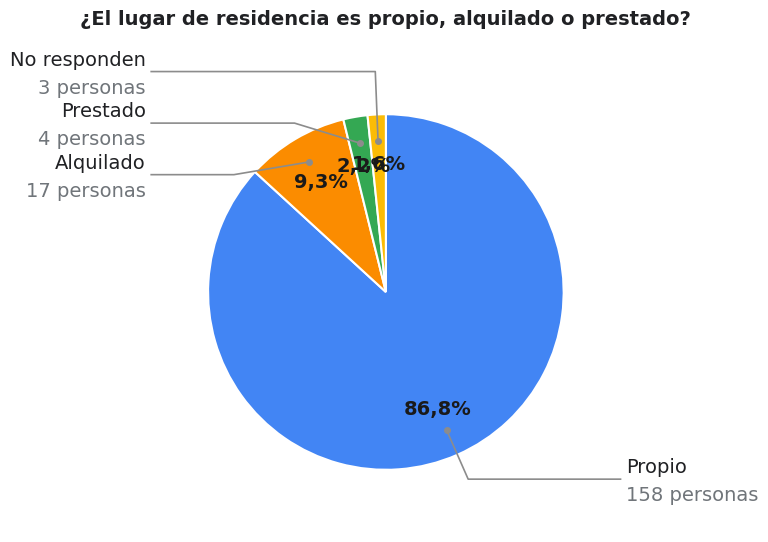

In [6]:
# Ejemplo 1: Torta normal (4 categorías) con línea directa que no subraya
categorias_ejemplo = ['Propio', 'Alquilado', 'Prestado', 'No responden']
valores_ejemplo = [158, 17, 4, 3]

graficar_torta(
    categorias=categorias_ejemplo,
    valores=valores_ejemplo,
    titulo="¿El lugar de residencia es propio, alquilado o prestado?"
)


[INFO] La variable tiene 7 categorías (> 5). Se grafica con barras horizontales usando la paleta de torta.


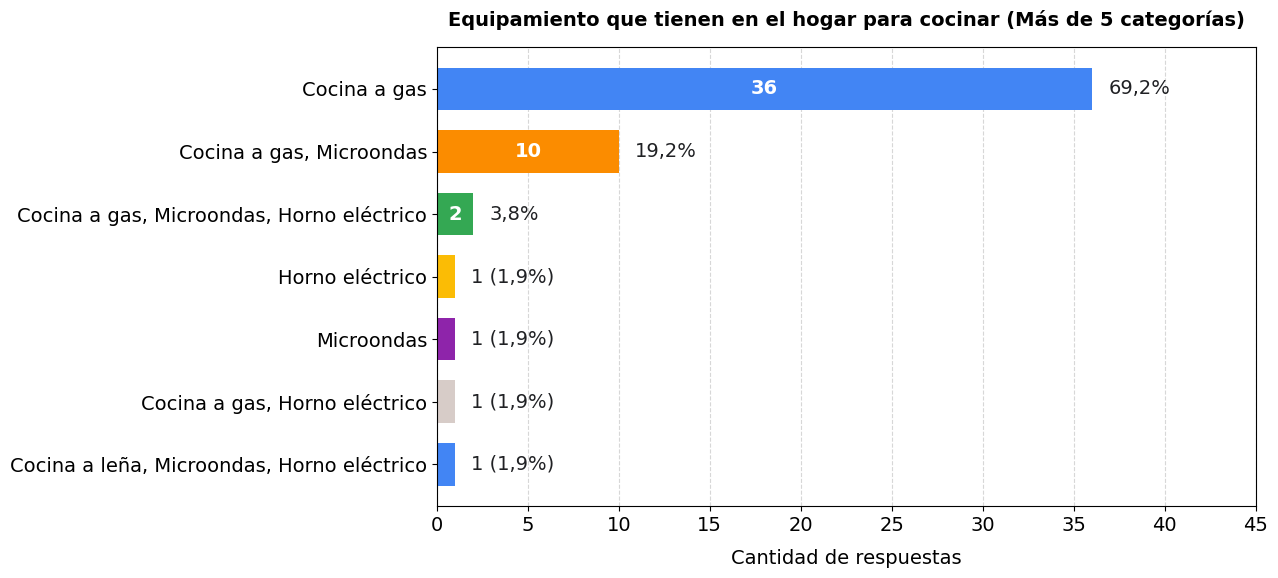

In [7]:
# Ejemplo 2: Variable con más de 5 categorías -> Conmuta automáticamente a barras con colores de torta
categorias_muchas = [
    'Cocina a gas',
    'Cocina a gas, Microondas',
    'Cocina a gas, Microondas, Horno eléctrico',
    'Horno eléctrico',
    'Microondas',
    'Cocina a gas, Horno eléctrico',
    'Cocina a leña, Microondas, Horno eléctrico'
]
valores_muchas = [36, 10, 2, 1, 1, 1, 1]

graficar_torta(
    categorias=categorias_muchas,
    valores=valores_muchas,
    titulo="Equipamiento que tienen en el hogar para cocinar (Más de 5 categorías)"
)


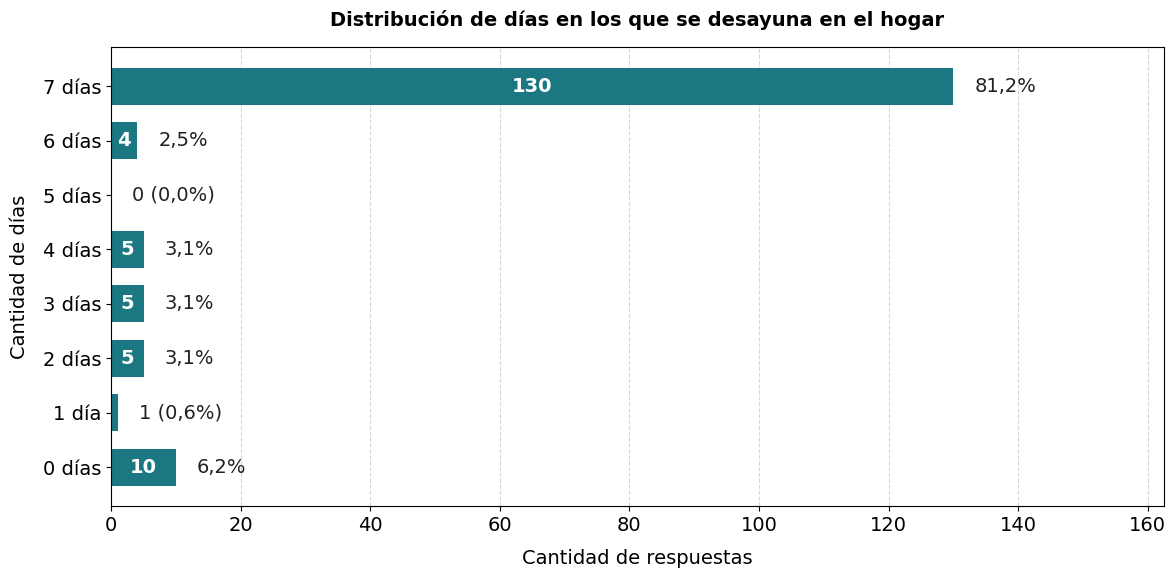

In [8]:
# Ejemplo 3: Barras horizontales con valores donde el porcentaje es < 2% (van afuera de la barra)
dias = [0, 1, 2, 3, 4, 5, 6, 7]
respuestas_dias = [10, 1, 5, 5, 5, 0, 4, 130]

graficar_barras_horizontales(
    etiquetas=dias,
    valores=respuestas_dias,
    titulo="Distribución de días en los que se desayuna en el hogar",
    xlabel="Cantidad de respuestas",
    ylabel="Cantidad de días",
    sufijo_etiqueta="días"
)


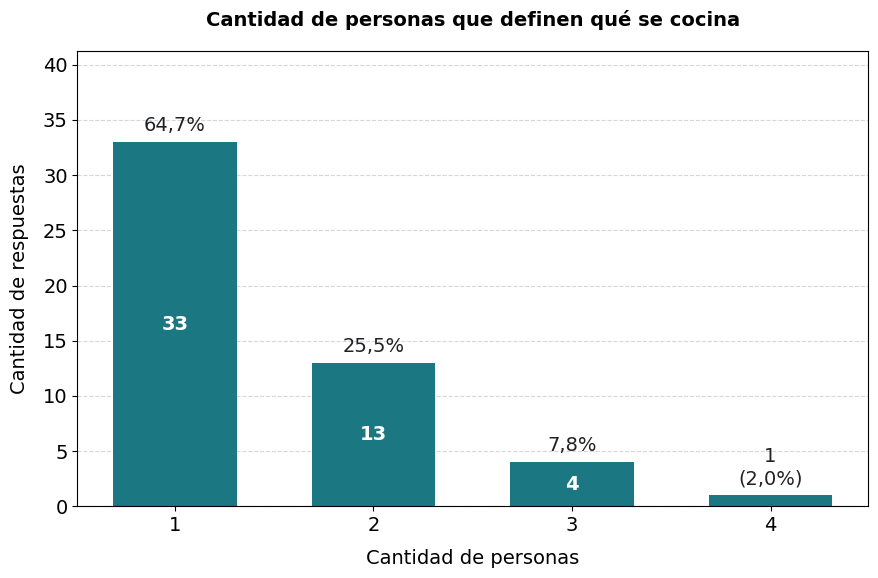

In [9]:
# Ejemplo 4: Barras verticales con valores donde el porcentaje es < 2%
personas = ['1', '2', '3', '4']
respuestas_personas = [33, 13, 4, 1] # 1 caso es < 2%

graficar_barras_verticales(
    etiquetas=personas,
    valores=respuestas_personas,
    titulo="Cantidad de personas que definen qué se cocina",
    xlabel="Cantidad de personas",
    ylabel="Cantidad de respuestas"
)


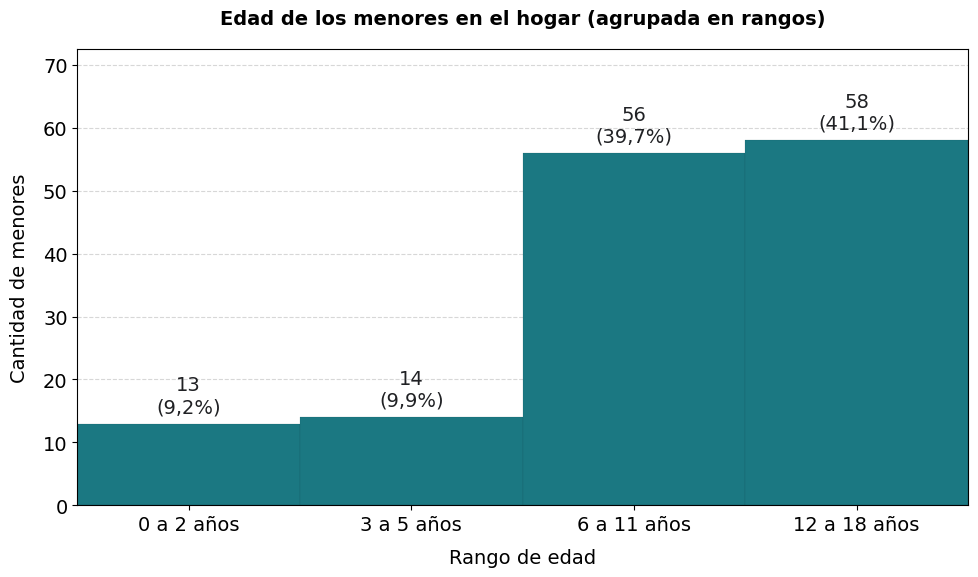

In [10]:
# Ejemplo 5: Histograma continuo de edades
rangos_edad = ['0 a 2 años', '3 a 5 años', '6 a 11 años', '12 a 18 años']
cantidades_menores = [13, 14, 56, 58]

graficar_histograma_intervalos(
    intervalos=rangos_edad,
    frecuencias=cantidades_menores,
    titulo="Edad de los menores en el hogar (agrupada en rangos)",
    xlabel="Rango de edad",
    ylabel="Cantidad de menores"
)


Cargando 'datos.csv'...
Dataset procesado con éxito. Total integrantes: 178


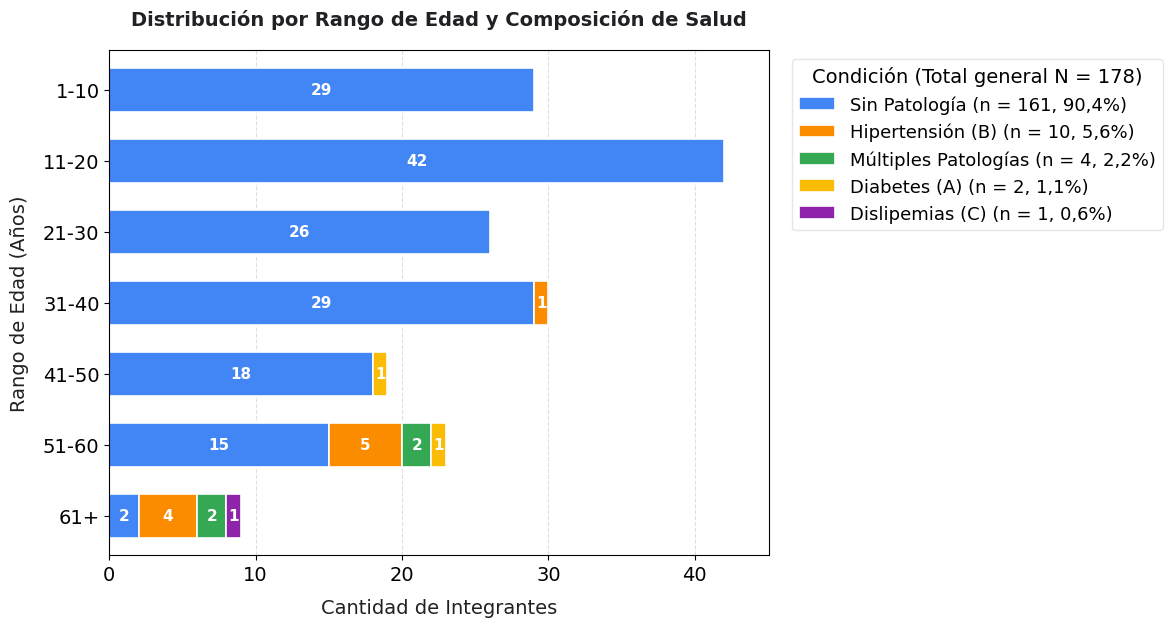

In [11]:
# Ejemplo 6: Gráfico de barras particionado (Rango de edad vs. Composición de salud)
# Si 'base proba.csv' o 'datos.csv' existe, procesa el archivo crudo desglosando por integrante.
# De lo contrario, utiliza la tabla de contingencia consolidada (N = 178) del informe.
try:
    try:
        df_salud_raw = pd.read_csv("base proba.csv")
        print("Cargando 'base proba.csv'...")
    except FileNotFoundError:
        df_salud_raw = pd.read_csv("datos.csv")
        print("Cargando 'datos.csv'...")

    # Desglosamos por integrante individual
    df_integrantes = procesar_desglose_integrantes_salud(df_salud_raw)
    tabla_salud = pd.crosstab(df_integrantes["Rango_Edad"], df_integrantes["Condicion"])
    print(f"Dataset procesado con éxito. Total integrantes: {len(df_integrantes)}")

except FileNotFoundError:
    print("Archivo CSV no encontrado. Utilizando datos consolidados del informe (N = 178).")
    tabla_salud = pd.DataFrame(
        {
            'Sin Patología': [29, 42, 26, 29, 18, 15, 2],
            'Hipertensión (B)': [0, 0, 0, 1, 0, 5, 4],
            'Múltiples Patologías': [0, 0, 0, 0, 0, 2, 2],
            'Diabetes (A)': [0, 0, 0, 0, 1, 1, 0],
            'Dislipemias (C)': [0, 0, 0, 0, 0, 0, 1]
        },
        index=["1-10", "11-20", "21-30", "31-40", "41-50", "51-60", "61+"]
    )

# Graficar con la función estandarizada
graficar_barras_particionadas(
    datos=tabla_salud,
    titulo="Distribución por Rango de Edad y Composición de Salud",
    xlabel="Cantidad de Integrantes",
    ylabel="Rango de Edad (Años)",
    titulo_leyenda="Condición",
    figsize=(12, 6.5)
)


## 6. Integración directa con `datos.csv`


Dataset cargado correctamente. Filas: 52 | Columnas: 342


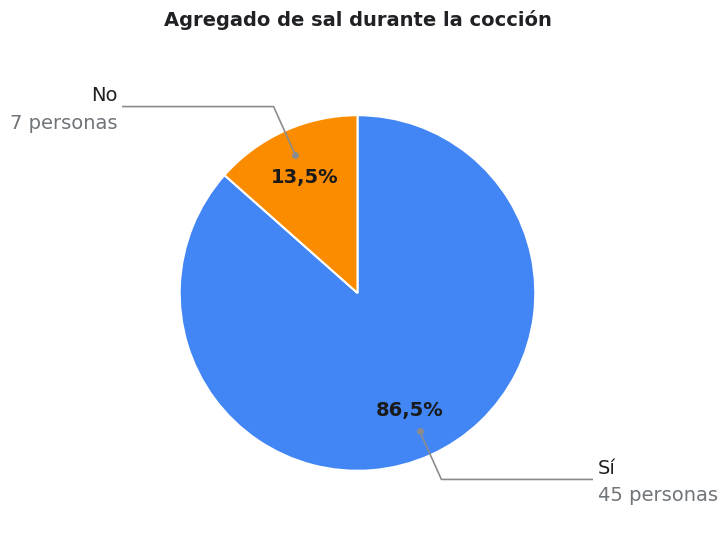

In [12]:
# Prueba de carga directa con datos.csv
try:
    df_datos = pd.read_csv('datos.csv')
    print("Dataset cargado correctamente. Filas:", len(df_datos), "| Columnas:", len(df_datos.columns))

    col_sal = '1.7 Habitualmente cuando se cocina en el hogar, ¿se le agrega sal a las comidas durante la cocción?'
    if col_sal in df_datos.columns:
        conteo_sal = df_datos[col_sal].value_counts()
        graficar_torta(
            categorias=conteo_sal.index,
            valores=conteo_sal.values,
            titulo="Agregado de sal durante la cocción",
            es_binario=True
        )
except FileNotFoundError:
    print("Archivo datos.csv no encontrado en el directorio actual.")
